# Sphere quotient dynamics

This notebook gives a reproducible version of the sphere experiment in Section 5.1. It introduces the physical flow and quotient coordinate, replays the released checkpoint, computes the learned ten-step Conley--Morse graph, checks the sampled pullback inequality, and displays the indices of the specified sphere lift.

Run the cells in order. The learned dynamics and quotient graphs are regenerated from the bundled checkpoint. The sphere-lift index annotations are supplied by the specified lift construction.

## Setup

The first code cell locates the repository and imports the plotting and replay utilities. `workspace` restores the analytical input bundle and verifies its recorded hashes. The learned checkpoint is verified separately by the replay step below.

The notebook uses the standard environment for plots and graph computations. The replay helper invokes the pinned EMLP environment only when it evaluates the saved neural networks. No training is required.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "upstream.json").is_file())
sys.path.insert(0, str(ROOT / "src"))
from notebook_support import workspace
ROOT, EXAMPLES, DATA = workspace()


Pinned dependencies 21acca6 and numerical input checksums verified.


## Sphere flow and physical quotient

For $p=(x,y,z)\in S^2=\{p\in\mathbb R^3:\|p\|=1\}$ and $e_3=(0,0,1)$, consider
$$\dot p=0.6e_3\times p+z(0.4^2-z^2)(e_3-zp).$$
The physical quotient $q:S^2\to[-1,1]$, $q(p)=p_3$, identifies the circles of constant height. Its flow maps $h_t:[-1,1]\to[-1,1]$ solve
$$\dot z=z(0.4^2-z^2)(1-z^2).$$
Removing the known rotation gives an $O(2)$-equivariant flow $F_t:S^2\to S^2$ with this same height equation. Training uses $F_1$, and the CMGDB comparison uses $h_{10}$.

For example, $(\sqrt3/2,0,1/2)$ and $(0,\sqrt3/2,1/2)$ both have height $1/2$ and belong to the same orbit. Their quotient velocity is
$$\dot z=\tfrac12(0.16-0.25)(1-0.25)=-0.03375,$$
so that latitude moves toward $z=0.4$. Factoring the height equation gives fixed heights $-1,-0.4,0,0.4,1$. The poles and equator repel in height, while the circles at $\pm0.4$ attract. Rotation along the attracting circles continues.

The next cell evaluates the three-dimensional vector field on the visible hemisphere. It projects both the sphere and its tangent vectors onto a plane viewed from an elevation of $18^\circ$. The projection $P:\mathbb R^3\to\mathbb R^2$ is $P(p)=(p\cdot u,p\cdot w)$, where $u,w$ are orthonormal screen directions. The unit vector $d$ points toward the viewer, so $p\cdot d\geq0$ identifies the front hemisphere.

Arrows have equal length in three dimensions before projection, showing direction rather than speed. This is a vector-field plot, not a collection of simulated trajectories. Faint portions of the invariant circles lie behind the sphere. NumPy constructs the points and vectors, and Matplotlib draws their projections.


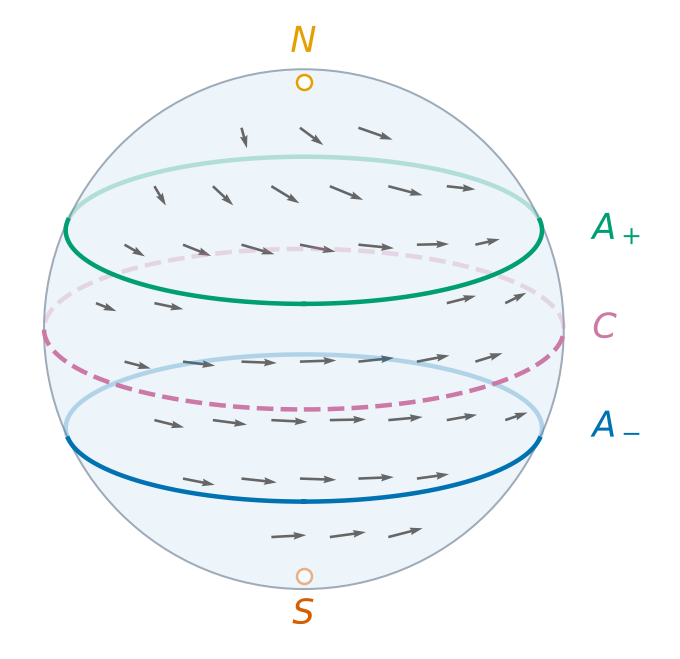

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import Image, display

# Evaluate the stated vector field at an array of sphere points.
def sphere_field(points):
    z = points[:, 2]
    rotation = 0.6 * np.column_stack((-points[:, 1], points[:, 0], 0*z))
    return rotation + (z*(0.16-z*z))[:, None] * (np.array([0, 0, 1])-z[:, None]*points)

# Orthographic camera and screen coordinates.
elevation = np.deg2rad(18)
d = np.array([np.cos(elevation), 0, np.sin(elevation)])
u = np.array([0, 1, 0])
w = np.cross(d, u)
def project(points):
    return np.column_stack((points @ u, points @ w))

# Lift a staggered screen grid to the front unit hemisphere.
points = []
for row, b in enumerate(np.linspace(-0.8, 0.775, 8)):
    for a in np.arange(-0.8 + (row % 2)*0.11, 0.86, 0.225):
        if a*a+b*b < 0.87**2:
            p = a*u + b*w + np.sqrt(1-a*a-b*b)*d
            if np.min(np.abs(p[2]-np.array([-0.4, 0, 0.4]))) > 0.04:
                points.append(p)
points = np.array(points)
vectors = sphere_field(points)
assert np.max(np.abs(np.sum(points*vectors, axis=1))) < 1e-12  # tangency
arrows = project(0.14*vectors / np.linalg.norm(vectors, axis=1)[:, None])
base = project(points)

fig, ax = plt.subplots(figsize=(5.4, 4.5))
ax.add_patch(Circle((0, 0), 1, facecolor='#edf4fa', edgecolor='#9eabb8', lw=0.8))
ax.quiver(base[:, 0], base[:, 1], arrows[:, 0], arrows[:, 1],
          angles='xy', scale_units='xy', scale=1, width=0.004, color='0.4')
phi = np.linspace(0, 2*np.pi, 1001)
for height, color, label in [(-0.4, '#0072b2', r'$A_-$'),
                              (0, '#cc79a7', '$C$'), (0.4, '#009e73', r'$A_+$')]:
    radius = np.sqrt(1-height**2)
    circle = np.column_stack((radius*np.cos(phi), radius*np.sin(phi), height+0*phi))
    screen = project(circle)
    for front in (False, True):
        visible = (circle @ d >= 0) == front
        line = np.where(visible[:, None], screen, np.nan)
        ax.plot(line[:, 0], line[:, 1], '--' if height == 0 else '-',
                color=color, alpha=1 if front else 0.25, lw=1.8)
    ax.text(1.11, height*np.cos(elevation), label, color=color, fontsize=14, va='center')
for height, label, color in [(1, '$N$', '#e69f00'), (-1, '$S$', '#d55e00')]:
    x, y = project(np.array([[0, 0, height]]))[0]
    ax.plot(x, y, 'o', mfc='white', mec=color, alpha=1 if height > 0 else 0.45)
    ax.text(0, 1.10*height, label, ha='center', va='center', fontsize=14, color=color)
ax.set(aspect='equal', xlim=(-1.1, 1.38), ylim=(-1.2, 1.2))
ax.axis('off')
figure_dir = ROOT / 'build/notebooks/sphere/analytical'
figure_dir.mkdir(parents=True, exist_ok=True)
for extension in ('png', 'pdf', 'svg'):
    fig.savefig(figure_dir / f'sphere-field.{extension}', dpi=180, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(figure_dir / 'sphere-field.png'), width=540))

### Height map

To compute $h_3(z_0)$, start the scalar ODE at $z_0$ and integrate for three time units. `solve_ivp` from SciPy performs adaptive numerical integration with the displayed tolerances. Passing the independent initial heights as a vector computes the whole curve in one call. The extra points near the poles resolve its steep ends.

The gray diagonal is the identity. Its intersections with $h_3$ are the five fixed heights. Filled markers indicate attraction in height, and open markers indicate repulsion. The assertions check these fixed values and agreement with a second integration at tighter tolerances on the plotted grid. They are numerical checks, not uniform error bounds.


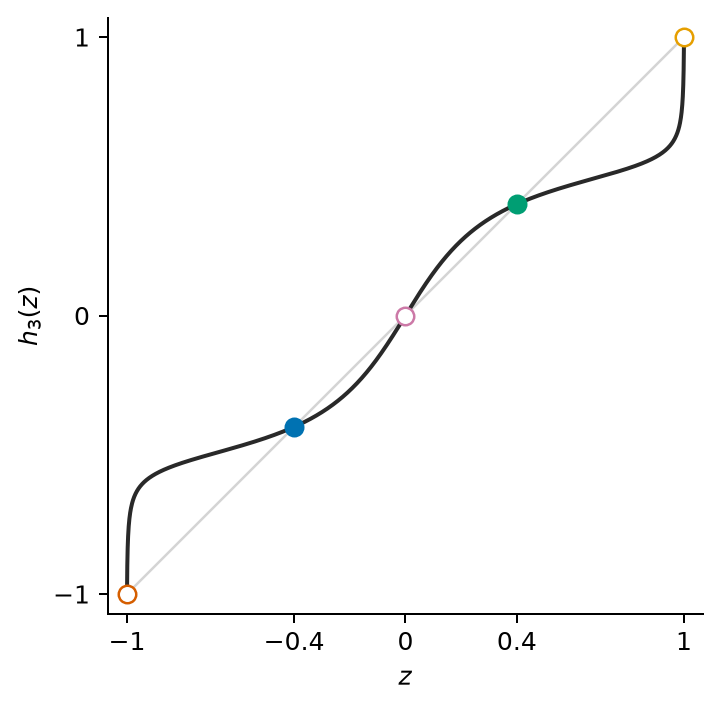

In [3]:
from scipy.integrate import solve_ivp

def height_velocity(t, z):
    return z*(0.16-z*z)*(1-z*z)

def height_flow(z0, duration, rtol=1e-10, atol=1e-12):
    solution = solve_ivp(height_velocity, (0, duration), np.asarray(z0, dtype=float),
                         method='DOP853', rtol=rtol, atol=atol)
    assert solution.success, solution.message
    return solution.y[:, -1]

z = np.unique(np.r_[np.linspace(-1, 1, 1401),
                    1-10.**(-np.linspace(1, 12, 300)),
                    -1+10.**(-np.linspace(1, 12, 300)), -0.4, 0.4])
h = height_flow(z, 3)
fixed = np.array([-1, -0.4, 0, 0.4, 1])
assert np.max(np.abs(height_flow(fixed, 3)-fixed)) < 1e-12
assert np.max(np.abs(h-height_flow(z, 3, rtol=1e-12, atol=1e-14))) < 1e-8
assert np.min(np.diff(h)) >= -1e-10

fig, ax = plt.subplots(figsize=(4.6, 4.3))
ax.plot([-1, 1], [-1, 1], color='0.83', lw=1)
ax.plot(z, h, color='0.16', lw=1.6)
colors = ['#d55e00', '#0072b2', '#cc79a7', '#009e73', '#e69f00']
for value, color in zip(fixed, colors):
    ax.plot(value, value, 'o', mec=color, mfc=color if abs(value) == 0.4 else 'white', ms=7)
ax.set(aspect='equal', xlim=(-1.07, 1.07), ylim=(-1.07, 1.07), xlabel='$z$', ylabel='$h_3(z)$')
ax.set_xticks(fixed, ['−1', '−0.4', '0', '0.4', '1'])
ax.set_yticks([-1, 0, 1])
ax.spines[['top', 'right']].set_visible(False)
for extension in ('png', 'pdf', 'svg'):
    fig.savefig(figure_dir / f'height-map.{extension}', dpi=180, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(figure_dir / 'height-map.png'), width=460))

## Encoder, time-step map, and decoder

The invariant encoder $E_\theta:S^2\to[-1,1]$ assigns one coordinate to each rotation orbit. The learned map $f_\psi:[-1,1]\to[-1,1]$ advances that coordinate by one time unit. The neural decoder returns a scalar height,

$$
\widehat z_\phi:\mathbb R\to[-1,1].
$$

Composing it with the longitude-zero section $s(z)=(\sqrt{1-z^2},0,z)$ gives a representative decoder $D_\phi=s\circ\widehat z_\phi:\mathbb R\to S^2$. Reconstruction is therefore understood up to the rotation action.

The interval map preserves its endpoints through

$$
f_\psi(q)=\frac{q+t_\psi(q)}{1+q\,t_\psi(q)},
\qquad
t_\psi(q)=\tanh\!\left(3\tanh\!\left(N_\psi(q)/3\right)\right).
$$

## Joint initialization

For training pairs (p^+=F_1(p)), the encoder, interval map, and height decoder are initialized jointly with reconstruction, prediction, and latent-consistency losses:

$$
\mathcal L=\mathcal L_{\mathrm{rec}}+\mathcal L_{\mathrm{pred}}+\mathcal L_{\mathrm{con}},
$$

$$
\mathcal L_{\mathrm{rec}}
=\mathbb E\,d_G\!\left(D_\phi(E_\theta(p)),p\right)^2,
\qquad
\mathcal L_{\mathrm{pred}}
=\mathbb E\,d_G\!\left(D_\phi(f_\psi(E_\theta(p))),p^+\right)^2,
$$

$$
\mathcal L_{\mathrm{con}}
=\mathbb E\left\|f_\psi(E_\theta(p))-E_\theta(p^+)\right\|^2,
$$

where $d_G$ is distance modulo rotations about $e_3$. This joint objective supplies the initialization used by the released checkpoint. The final dynamics-only step is specified next.

## Released checkpoint

The released checkpoint keeps the trained encoder and decoder fixed and updates only the latent map. Define the $k$-step latent residual

$$
r_k(p)=f_\psi^k(E_\theta(p))-E_\theta(F_k(p)).
$$

The final objective is the mean squared ten-step residual plus the mean of the largest 32 squared ten-step residuals in each batch, together with $0.1$ times the mean squared one-step residual. Model selection uses the smallest validation maximum of $|r_{10}|$.

The bundled manifest pins the checkpoint hash and the expected graph and pullback outputs. The next cell recomputes those outputs and raises an error if any pinned value changes.

In [4]:
from sphere_passing_replay import (
    replay,
    show_dynamics,
    show_pullback_check,
    show_reconstruction,
)

verification = replay()
print("Checkpoint and numerical gate verified.")

Checkpoint and numerical gate verified.


## Learned ten-step dynamics

For $z\in[-1,1]$, let $p_z=(\sqrt{1-z^2},0,z)$. The curve plots the decoded height

$$
\widehat z_\phi\!\left(f_\psi^{10}(E_\theta(p_z))\right).
$$

The gray diagonal marks unchanged height. Colored markers locate the encoder preimages of the learned fixed points.


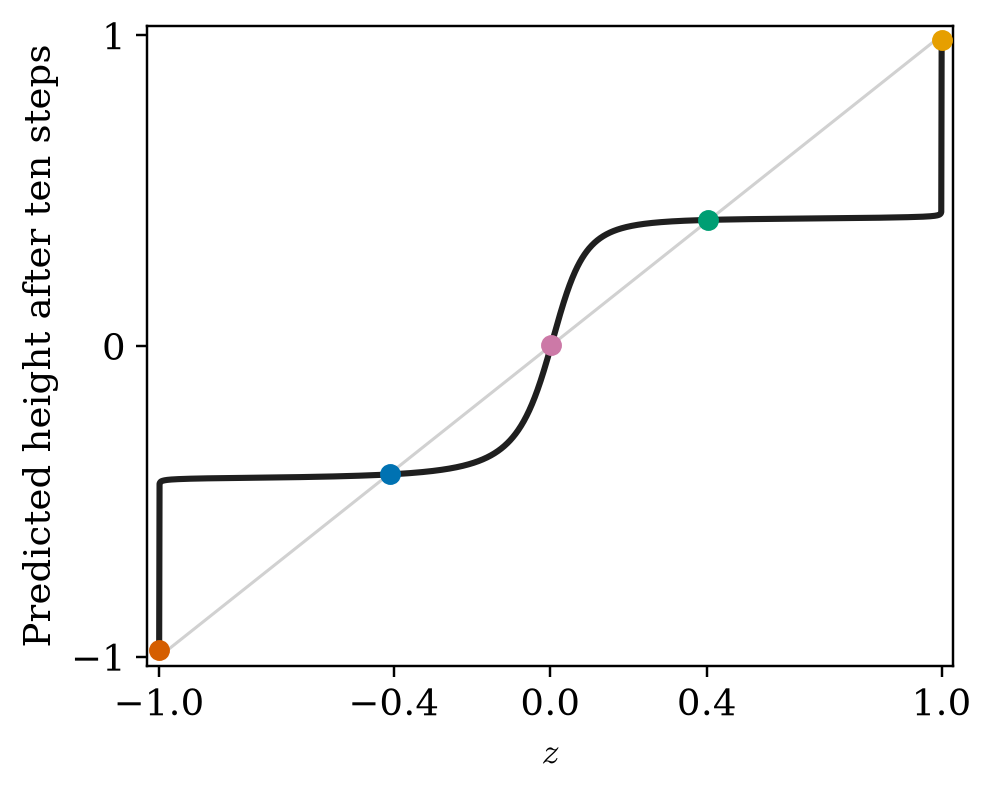

In [5]:
show_dynamics()

## Pullback check

Let $N_-$ and $N_+$ be the unions of interval cells from which only the attracting component $A_-$ or $A_+$, respectively, is reachable. For each block, the tolerance is the sampled distance from its cell-image hulls to the boundary of the block. The residual is

$$
\left|f_\psi^{10}(E_\theta(p))-E_\theta(F_{10}(p))\right|.
$$

The replay evaluates this residual on 69,537 meridian samples, with additional resolution near the poles, and uses 65 image samples per cell for the block calculation. On the 128-cell grid, both sampled residual maxima lie below their corresponding tolerances. This is the numerical comparison used for Proposition 4.2(ii). Because both quantities are sampled, it is not a uniform error bound.

In [6]:
show_pullback_check(verification)

Block,Cells,Tolerance,Maximum sampled residual,Residual below tolerance
A-,57,0.04137,0.00726,yes
A+,67,0.05667,0.00738,yes


## Analytical and learned Morse graphs

The columns compare the analytical system with the learned model. The top row shows the analytical Morse-cell preimages under the height projection and the learned Morse-cell preimages under the encoder. The interval row shows their locations in physical height $z$ and learned coordinate $q$, respectively. The same labels and colors identify corresponding components throughout.

The quotient graphs use 128 interval cells. For the learned map, cell images use 1,025 samples per cell. Two adjacent Morse components and their connecting cells are grouped, and their index pair is recomputed, giving five nodes. Under the displayed labels, the two graphs have identical directed edges and quotient-index annotations. Their cell locations need not coincide. The sampled cell images are numerical approximations, not certified enclosures.

The bottom row shows the sphere-lift indices, listed in increasing homological degree. These tuples are supplied by the specified lift construction, rather than independently computed by this replay. Graph arrows record connections between components. The arrows beside the spheres only identify the colored bands. The sampled residual comparison above is a separate check.


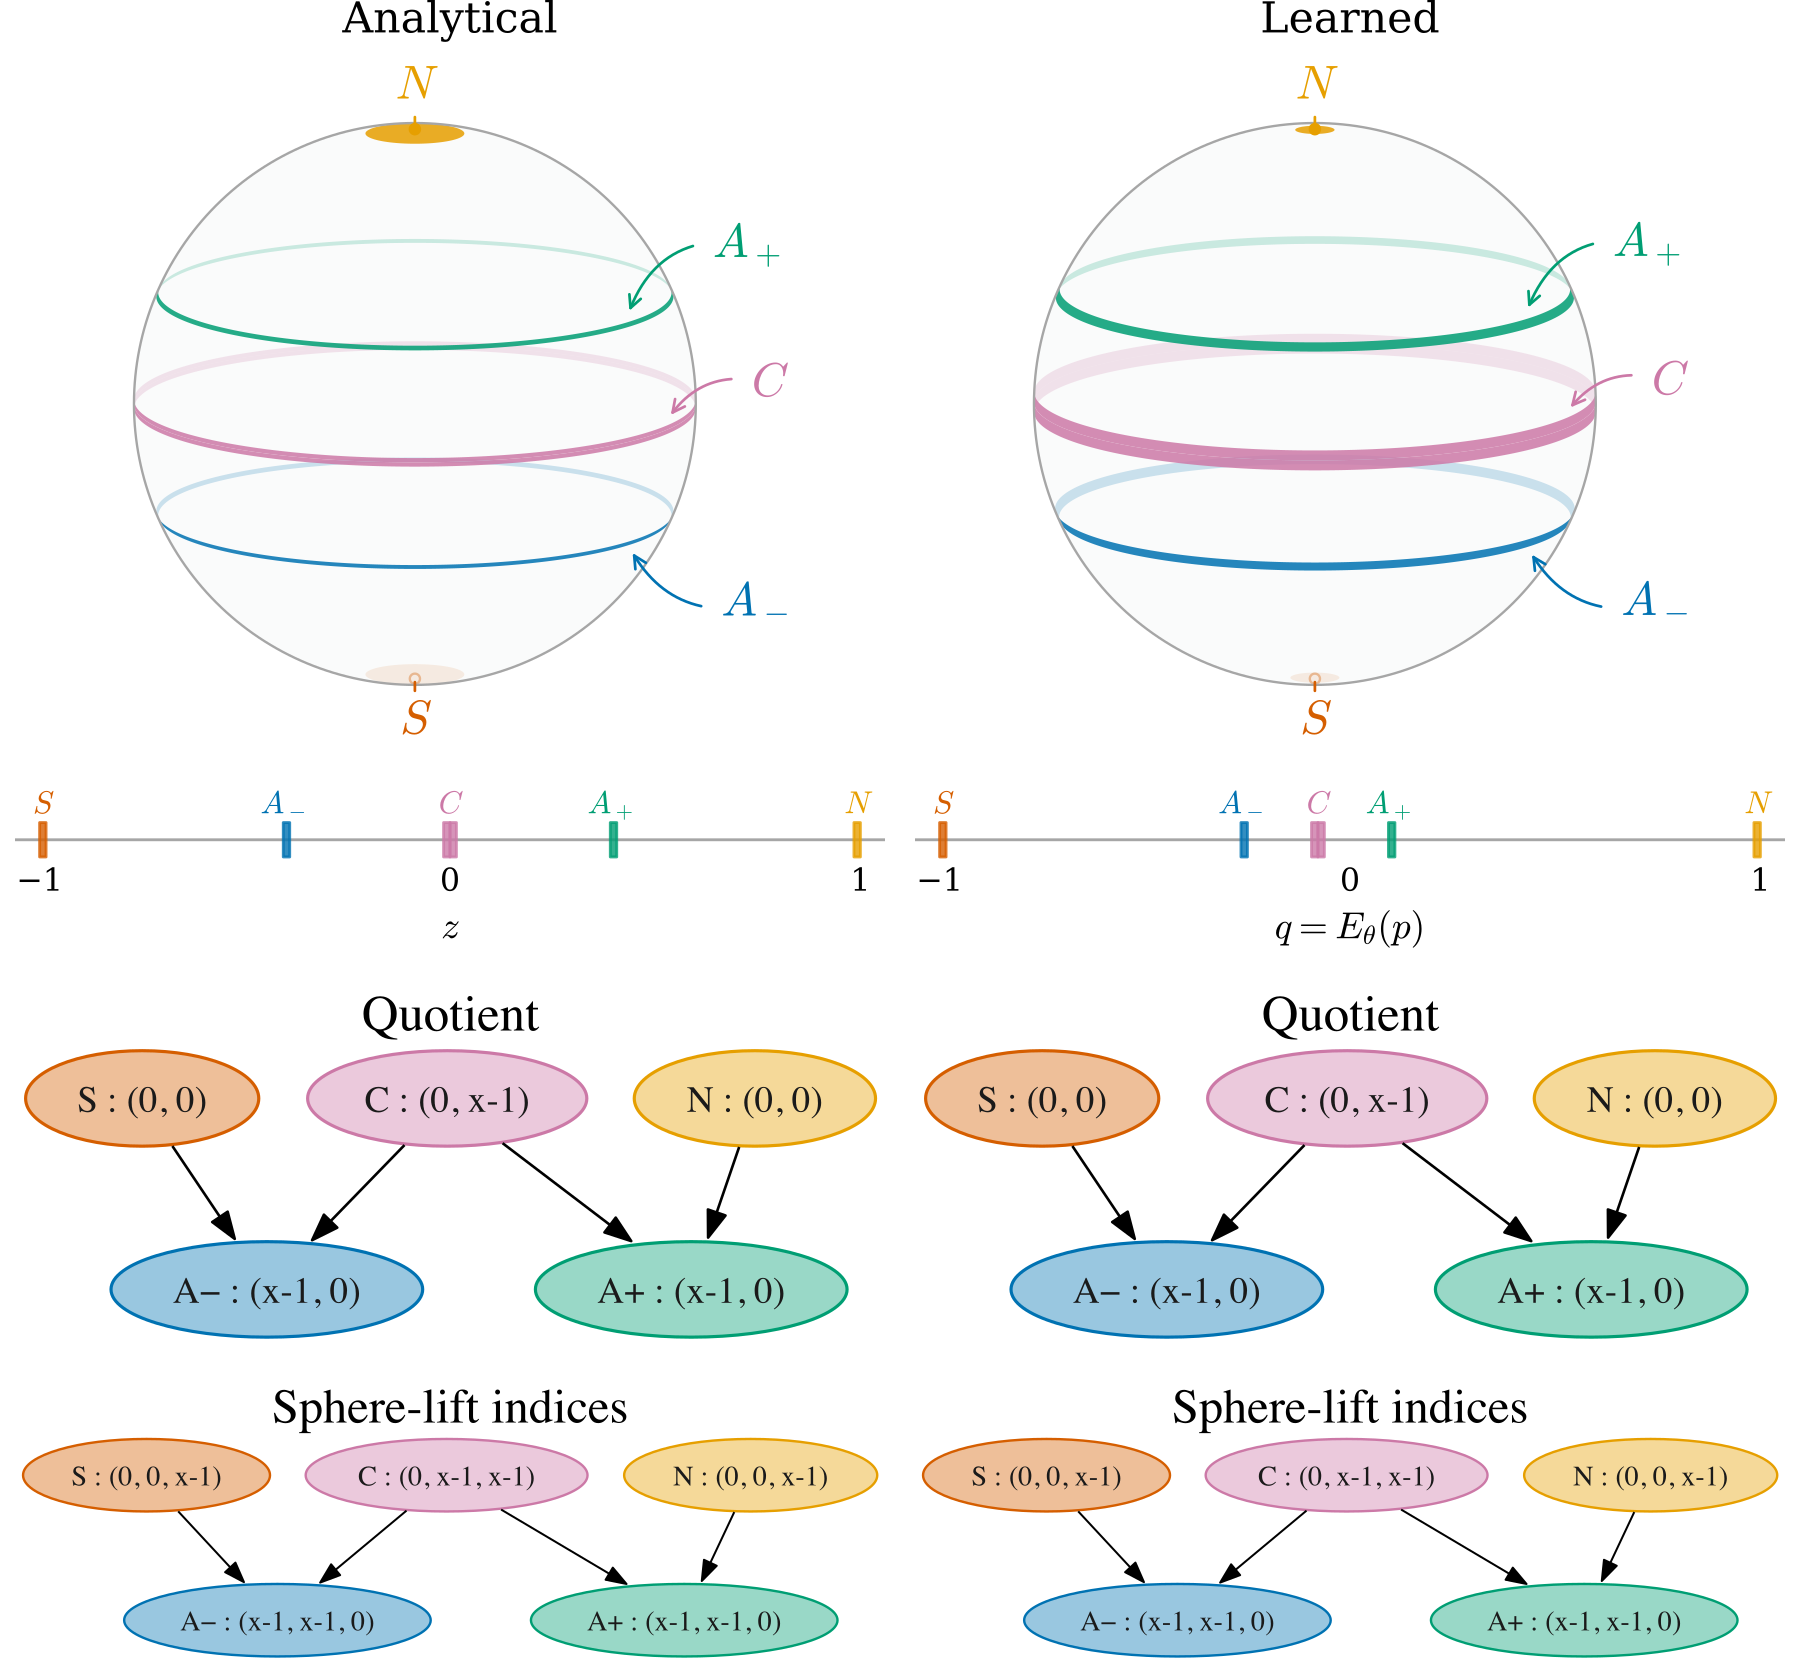

In [7]:
show_reconstruction()

## Reproducibility record

The manifest records the checkpoint SHA-256 digest, graph grouping, block definitions, sampled residuals, and tolerances. The replay cell checks all of them before any learned result is displayed.

In [8]:
from IPython.display import JSON

JSON({
    "checkpoint_sha256": verification["checkpoint_sha256"],
    "grid_cells": verification["grid_cells"],
    "native_morse_components": verification["native_morse_components"],
    "grouped_morse_nodes": len(verification["grouped_graph"]["groups"]),
    "blocks": verification["blocks"],
    "sampled_estimates": verification["sampled_estimates"],
    "uniform_bound": verification["uniform_bound"],
})

<IPython.core.display.JSON object>